# PBL-III: Ensemble Learning for Crop Recommendation
**Project:** Harvestify – Intelligent AgTech Solution

## Problem statement
Choosing a crop that suits the soil and climate of a field is a key decision for a farmer. Given soil nutrient levels (N, P, K), soil pH and climate conditions (temperature, humidity, rainfall), the task is to **predict the most suitable crop out of 22 crops**. This is a **multiclass classification** problem, and it is the model behind Harvestify's crop recommendation feature.

## Objectives
1. Verify and briefly explore the crop recommendation dataset.
2. Train five baseline classifiers as a reference point.
3. Implement six ensemble methods: Bagging, Random Forest, AdaBoost, Gradient Boosting, Voting and Stacking.
4. Compare all models under identical conditions (same stratified 80:20 split, same metrics).
5. Identify the best ensemble method, check whether it beats the single models, then evaluate, interpret and save it.

| Rubric criterion | Sections |
|---|---|
| Problem identification and dataset selection (4) | 1, 2 |
| Implementation of ensemble learning approaches (8) | 3, 4, 5 |
| Comparative performance analysis (4) | 6 |
| Result interpretation and presentation (4) | 7, 8 |


## Before running

Run this notebook from the Harvestify project, with the project environment selected as the kernel. The dataset must be available at `Data-processed/crop_recommendation.csv` and the project root must contain the `models/` folder. The path-detection cell searches the current directory and its parents, so the notebook can be opened from either the project root or `notebooks/`.

**Execution:** choose **Kernel → Restart Kernel and Run All Cells**. Allow the model-training and cross-validation cells to finish; they can take a few minutes.


In [77]:
import json, time
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier, GradientBoostingClassifier,
                              RandomForestClassifier, StackingClassifier, VotingClassifier)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

# Locate the project root, so the notebook works from notebooks/ or from the project root
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "Data-processed" / "crop_recommendation.csv").exists())
DATA_PATH = ROOT / "Data-processed" / "crop_recommendation.csv"
MODEL_DIR = ROOT / "models"
print("Data file:", DATA_PATH)
print("scikit-learn", sklearn.__version__)

Data file: C:\Users\rajvi\Downloads\Harvestify-master 2\Data-processed\crop_recommendation.csv
scikit-learn 1.9.1


## 2. Dataset description and EDA
**Source:** `Data-processed/crop_recommendation.csv`, Harvestify's processed version of the public Kaggle *Crop Recommendation* dataset. The checks below verify its size, features, target and quality directly from the file.


In [76]:
df = pd.read_csv(DATA_PATH)
FEATURES = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
TARGET = "label"

print("Shape (rows, columns):", df.shape)
print("Columns:", df.columns.tolist())
print("Feature columns present and numeric:",
      all(c in df and pd.api.types.is_numeric_dtype(df[c]) for c in FEATURES))
print("Missing values:", int(df.isna().sum().sum()), "| Duplicate rows:", int(df.duplicated().sum()))
counts = df[TARGET].value_counts()
print(f"Crop classes: {df[TARGET].nunique()} | samples per class: min {counts.min()}, max {counts.max()}")
df[FEATURES].describe().T.round(2)

Shape (rows, columns): (2200, 8)
Columns: ['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']
Feature columns present and numeric: True
Missing values: 0 | Duplicate rows: 0
Crop classes: 22 | samples per class: min 100, max 100


,count,mean,std,min,25%,50%,75%,max
N,2200.0,50.55,36.92,0.00,21.00,37.00,84.25,140.00
P,2200.0,53.36,32.99,5.00,28.00,51.00,68.00,145.00
K,2200.0,48.15,50.65,5.00,20.00,32.00,49.00,205.00
temperature,2200.0,25.62,5.06,8.83,22.77,25.60,28.56,43.68
humidity,2200.0,71.48,22.26,14.26,60.26,80.47,89.95,99.98
ph,2200.0,6.47,0.77,3.50,5.97,6.43,6.92,9.94
rainfall,2200.0,103.46,54.96,20.21,64.55,94.87,124.27,298.56


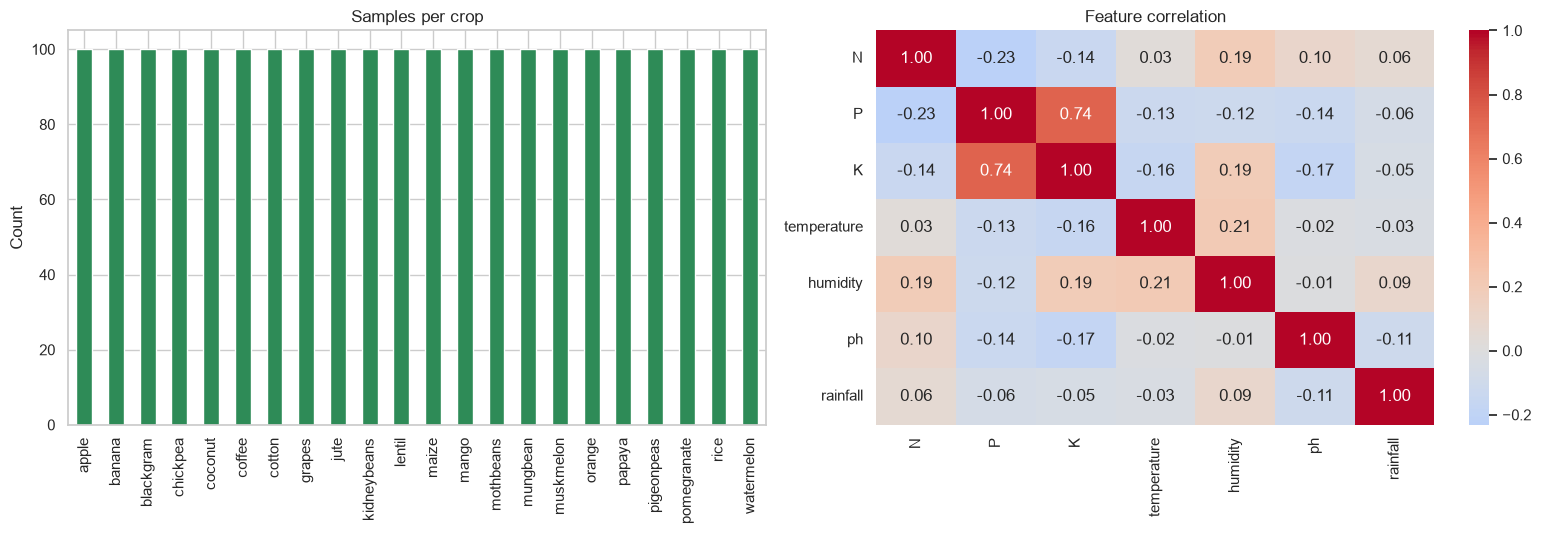

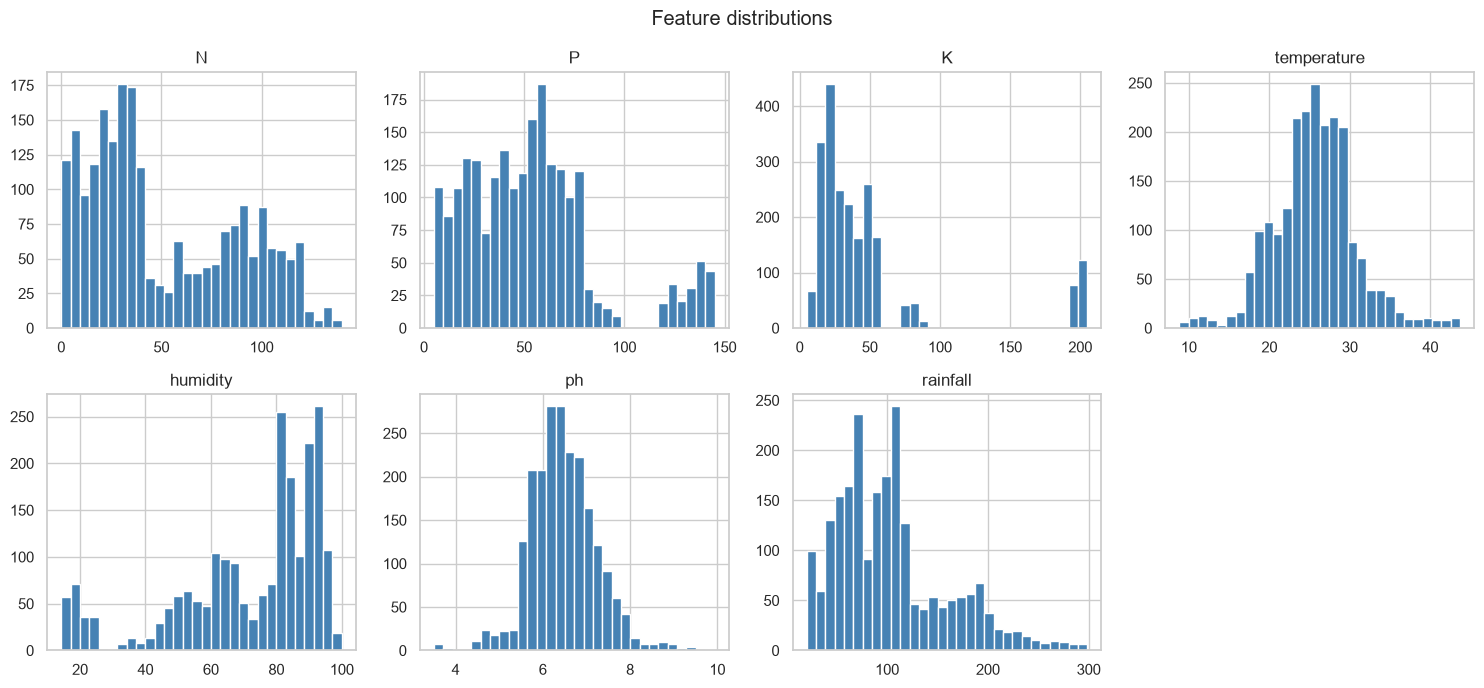

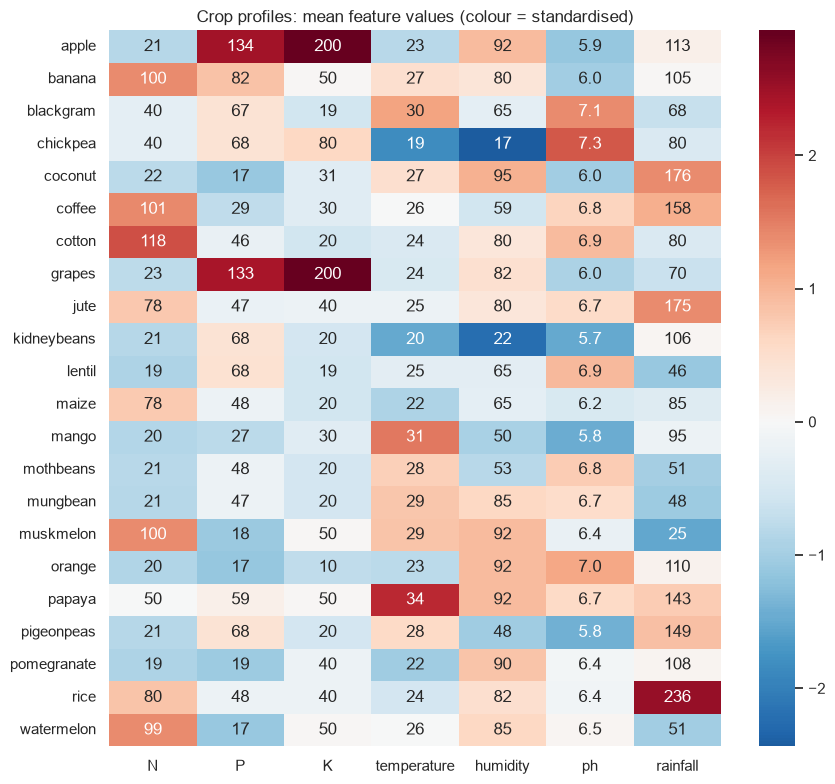

In [78]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
counts.sort_index().plot.bar(ax=axes[0], color="seagreen")
axes[0].set(title="Samples per crop", xlabel="", ylabel="Count")
sns.heatmap(df[FEATURES].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Feature correlation")
plt.tight_layout(); plt.show()

df[FEATURES].hist(bins=30, figsize=(15, 7), layout=(2, 4), color="steelblue", edgecolor="white")
plt.suptitle("Feature distributions"); plt.tight_layout(); plt.show()

# Mean of each feature per crop, standardised per feature: each crop's "growing profile"
profile = df.groupby(TARGET)[FEATURES].mean()
plt.figure(figsize=(9, 8))
annot = profile.apply(lambda col: col.map(("{:.1f}" if col.name == "ph" else "{:.0f}").format))
sns.heatmap((profile - profile.mean()) / profile.std(), cmap="RdBu_r", center=0, annot=annot, fmt="")
plt.title("Crop profiles: mean feature values (colour = standardised)"); plt.ylabel("")
plt.tight_layout(); plt.show()

**EDA findings**
- The dataset is **perfectly balanced**, so accuracy is a fair headline metric. Macro and weighted averages coincide here, because every test class has the same support.
- Features are mostly weakly correlated. The one strong pair is **P and K**, driven by apple and grapes, which need very high amounts of both.
- **K, P and rainfall are right-skewed and humidity is left-skewed.** The extreme values are real crop groups (for example K ≈ 200 for apple and grapes), not errors, so no outliers are removed.
- Features sit on very different scales (pH ≈ 3.5–10, rainfall ≈ 20–300 mm). Distance- and gradient-based models (KNN, SVM, Logistic Regression) therefore need scaling, while tree-based models do not.
- Each crop has a distinctive profile (heatmap), which suggests the classes are highly separable. Very high accuracy is expected from strong models.


## 3. Preprocessing and stratified 80:20 split
- No imputation, deduplication or encoding is needed (the checks above). scikit-learn classifiers accept the string crop labels directly.
- **Stratified** split, so every crop keeps the same proportion (80 train / 20 test each).
- **Leakage prevention:** scaling is placed *inside* a `Pipeline` for KNN, SVM and Logistic Regression, so the scaler is fitted on training data only (and only on the training folds during cross-validation). Naive Bayes and all tree-based models are scale-invariant, so they get raw features.


In [79]:
X, y = df[FEATURES], df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Per-class counts  train:", sorted(y_train.value_counts().unique()),
      " test:", sorted(y_test.value_counts().unique()))

scaled = lambda est: make_pipeline(StandardScaler(), est)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results, fitted, test_preds = [], {}, {}

def evaluate(name, family, model):
    # Fit on the training set, then score on the common test set
    start = time.perf_counter()
    model.fit(X_train, y_train)
    train_time = time.perf_counter() - start
    y_pred = model.predict(X_test)
    results.append({
        "Model": name, "Type": family,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score": f1_score(y_test, y_pred, average="macro", zero_division=0),
        "Training time (s)": train_time,
    })
    fitted[name], test_preds[name] = model, y_pred
    r = results[-1]
    print(f"{name:28s} accuracy {r['Accuracy']:.4f}  F1 {r['F1-score']:.4f}  ({train_time:.2f}s)")

Train: (1760, 7) | Test: (440, 7)
Per-class counts  train: [np.int64(80)]  test: [np.int64(20)]


## 4. Baseline models
Five single models from different families. Each is a reference point that the ensembles must beat.


In [81]:
baselines = {
    "Gaussian Naive Bayes": GaussianNB(),
    "Logistic Regression": scaled(LogisticRegression(max_iter=2000, random_state=RANDOM_STATE)),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "KNN (k=5)": scaled(KNeighborsClassifier(n_neighbors=5)),
    "SVM (RBF)": scaled(SVC(kernel="rbf", random_state=RANDOM_STATE)),
}
for name, model in baselines.items():
    evaluate(name, "Baseline", model

SyntaxError: incomplete input (1890686708.py, line 9)

## 5. Ensemble learning methods
| Method | Idea | Configuration |
|---|---|---|
| **Bagging** | Trains many trees on bootstrap samples and votes. Reduces variance | 100 decision trees |
| **Random Forest** | Bagging plus a random subset of features at each split, which decorrelates the trees | 200 trees |
| **AdaBoost** | Trains weak learners in sequence, re-weighting the samples earlier learners got wrong | default, then tuned (5.1) |
| **Gradient Boosting** | Each new tree fits the remaining errors (gradients of the loss) | 100 trees, depth 3, learning rate 0.1 |
| **Voting (soft)** | Averages the predicted probabilities of different model types | Naive Bayes + SVM + Random Forest |
| **Stacking** | A meta-learner learns how to combine the base models' out-of-fold predictions | same three base models, Logistic Regression meta-learner, 5-fold |

The Voting and Stacking base models come from three different families (probabilistic, kernel and tree ensemble), so their errors are less likely to coincide. Soft voting needs class probabilities, which SVM does not produce natively, so inside the ensembles it is wrapped in `CalibratedClassifierCV`.


In [49]:
def diverse_base_models():
    return [("nb", GaussianNB()),
            ("svm", scaled(CalibratedClassifierCV(SVC(kernel="rbf", random_state=RANDOM_STATE), ensemble=False))),
            ("rf", RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE))]

ensembles = {
    "Bagging": BaggingClassifier(DecisionTreeClassifier(random_state=RANDOM_STATE),
                                 n_estimators=100, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "AdaBoost (default stumps)": AdaBoostClassifier(random_state=RANDOM_STATE),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "Voting (soft)": VotingClassifier(diverse_base_models(), voting="soft"),
    "Stacking": StackingClassifier(diverse_base_models(),
                                   final_estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                                   cv=cv),
}
for name, model in ensembles.items():
    evaluate(name, "Ensemble", model)

Bagging                      accuracy 0.9909  F1 0.9909  (1.45s)
Random Forest                accuracy 0.9955  F1 0.9955  (1.27s)
AdaBoost (default stumps)    accuracy 0.1750  F1 0.0856  (0.48s)
Gradient Boosting            accuracy 0.9886  F1 0.9887  (16.35s)
Voting (soft)                accuracy 0.9955  F1 0.9954  (2.54s)
Stacking                     accuracy 0.9977  F1 0.9977  (14.03s)


### 5.1 Investigating the poor AdaBoost result
AdaBoost with default settings performs far worse than every other model. The cell below diagnoses why, then tunes AdaBoost on the **training set only** with 5-fold cross-validation, so the test set stays untouched.


In [50]:
ada_default = fitted["AdaBoost (default stumps)"]
n_classes = y_train.nunique()
Xtr_np = X_train.to_numpy()   # AdaBoost's internal trees are fitted on arrays

print("Default weak learner:", ada_default.estimator_)
print("Classes a single stump can output:",
      sorted({len(np.unique(t.predict(Xtr_np))) for t in ada_default.estimators_}))
print(f"Weighted error of the stumps: {ada_default.estimator_errors_.min():.3f} - "
      f"{ada_default.estimator_errors_.max():.3f}  (SAMME accepts a learner if error < 1 - 1/K = {1 - 1/n_classes:.3f})")
print("Distinct crops predicted on the test set:",
      len(np.unique(test_preds["AdaBoost (default stumps)"])), "of", n_classes)

ada_grid = GridSearchCV(
    AdaBoostClassifier(DecisionTreeClassifier(random_state=RANDOM_STATE), n_estimators=200,
                       random_state=RANDOM_STATE),
    param_grid={"estimator__max_depth": [1, 2, 3, 4, 6], "learning_rate": [0.5, 1.0]},
    scoring="f1_macro", cv=cv, n_jobs=-1)
ada_grid.fit(X_train, y_train)

grid = pd.DataFrame(ada_grid.cv_results_["params"]).assign(cv_macro_f1=ada_grid.cv_results_["mean_test_score"])
grid.columns = ["max_depth", "learning_rate", "CV macro-F1"]
display(grid.pivot(index="max_depth", columns="learning_rate", values="CV macro-F1").round(4))
print("Best AdaBoost settings (by CV on the training set):", ada_grid.best_params_)

evaluate("AdaBoost (tuned)", "Ensemble", clone(ada_grid.best_estimator_))

Default weak learner: DecisionTreeClassifier(max_depth=1)
Classes a single stump can output: [2]
Weighted error of the stumps: 0.780 - 0.909  (SAMME accepts a learner if error < 1 - 1/K = 0.955)
Distinct crops predicted on the test set: 6 of 22


learning_rate,0.5,1.0
max_depth,,
1,0.3102,0.3025
2,0.8516,0.9679
3,0.9875,0.9892
4,0.9932,0.9909
6,0.9926,0.9920


Best AdaBoost settings (by CV on the training set): {'estimator__max_depth': 4, 'learning_rate': 0.5}
AdaBoost (tuned)             accuracy 0.9955  F1 0.9955  (3.17s)


**Why the default AdaBoost fails.** Its default weak learner is a depth-1 decision stump, which can split the data into only two groups, so it can output at most two of the 22 crops. Each stump therefore misclassifies roughly 90% of the (weighted) samples. That is still just below SAMME's acceptance threshold of 1 − 1/K ≈ 0.955, so every stump is accepted but contributes very little. After 50 rounds the ensemble predicts only a handful of the 22 crops.

**Fix.** Slightly stronger weak learners (deeper trees) can separate several crops at once. The grid search shows performance jumping sharply from depth 1 to depth 3 and above. The tuned AdaBoost is kept in the comparison alongside the default one, so the effect of the weak learner's strength is visible rather than hidden.


## 6. Model comparison
All models are evaluated on the **same held-out test set** (440 samples, 20 per crop). Precision, recall and F1 are **macro averages** over the 22 crops.

Because one test sample is worth 0.23 percentage points of accuracy, small differences between top models may be noise. Each model is therefore also scored with **5-fold stratified cross-validation on the training set** (macro-F1, mean ± std). These CV columns use only training data and are reported separately from the test metrics.

**Selection metric:** mean **CV macro-F1**. Models whose mean CV macro-F1 is within **0.001** of the highest score are treated as tied, because 0.001 corresponds to fewer than two of the 1,760 training predictions. Ties are broken by shorter training time. The test set is used only to report final performance, never to choose a model.

Two results are reported separately:
1. **Highest CV result overall** across all twelve models, baselines included. This shows whether ensembles actually outperform single models on this dataset.
2. **Selected ensemble model for Harvestify integration:** the best-performing ensemble under the same rule. This answers the project's ensemble-learning question, and it is the model evaluated in Section 7 and saved.


In [51]:
all_models = {**baselines, **ensembles, "AdaBoost (tuned)": ada_grid.best_estimator_}
cv_scores = {name: cross_val_score(clone(m), X_train, y_train, cv=cv, scoring="f1_macro", n_jobs=-1)
             for name, m in all_models.items()}

comparison = pd.DataFrame(results).set_index("Model")
comparison["CV macro-F1 (mean)"] = [cv_scores[m].mean() for m in comparison.index]
comparison["CV macro-F1 (std)"] = [cv_scores[m].std() for m in comparison.index]
comparison = comparison.sort_values("CV macro-F1 (mean)", ascending=False)

TIE = 0.001
def tied_group(table):
    # Models within TIE of the top mean CV macro-F1, fastest first
    top = table["CV macro-F1 (mean)"].max()
    return table[table["CV macro-F1 (mean)"] >= top - TIE].sort_values("Training time (s)").index.tolist()

top_cv_model = comparison.index[0]
tied_overall = tied_group(comparison)
tied_ensembles = tied_group(comparison[comparison["Type"] == "Ensemble"])
best_name = tied_ensembles[0]   # fastest ensemble among the tied top ensembles

print(f"Highest CV macro-F1 overall: {top_cv_model} ({comparison.loc[top_cv_model, 'Type']}), "
      f"{comparison.loc[top_cv_model, 'CV macro-F1 (mean)']:.4f}")
print(f"Tied within {TIE} of the top score: {tied_overall}")
print(f"Tied top ensembles: {tied_ensembles}")
print(f"Selected ensemble model for Harvestify integration: {best_name} "
      f"(fastest of the tied ensembles) -> evaluated in Section 7 and saved")
display(comparison.style.format(precision=4).highlight_max(
    subset=["Accuracy", "Precision", "Recall", "F1-score", "CV macro-F1 (mean)"], color="#c6efce"))

Highest CV macro-F1 overall: Gaussian Naive Bayes (Baseline), 0.9949
Tied within 0.001 of the top score: ['Gaussian Naive Bayes', 'Random Forest', 'Stacking']
Tied top ensembles: ['Random Forest', 'Stacking']
Selected ensemble model for Harvestify integration: Random Forest (fastest of the tied ensembles) -> evaluated in Section 7 and saved


,Type,Accuracy,Precision,Recall,F1-score,Training time (s),CV macro-F1 (mean),CV macro-F1 (std)
Model,,,,,,,,
Gaussian Naive Bayes,Baseline,0.9955,0.9959,0.9955,0.9954,0.0216,0.9949,0.0042
Stacking,Ensemble,0.9977,0.9978,0.9977,0.9977,14.0292,0.9943,0.0051
Random Forest,Ensemble,0.9955,0.9957,0.9955,0.9955,1.2749,0.9943,0.0048
AdaBoost (tuned),Ensemble,0.9955,0.9957,0.9955,0.9955,3.1686,0.9932,0.0039
Voting (soft),Ensemble,0.9955,0.9959,0.9955,0.9954,2.5384,0.9920,0.0071
Bagging,Ensemble,0.9909,0.9911,0.9909,0.9909,1.4545,0.9920,0.0067
Gradient Boosting,Ensemble,0.9886,0.9897,0.9886,0.9887,16.3485,0.9869,0.0036
Decision Tree,Baseline,0.9795,0.9806,0.9795,0.9794,0.0236,0.9852,0.0068
SVM (RBF),Baseline,0.9841,0.9856,0.9841,0.9840,0.0617,0.9788,0.0106


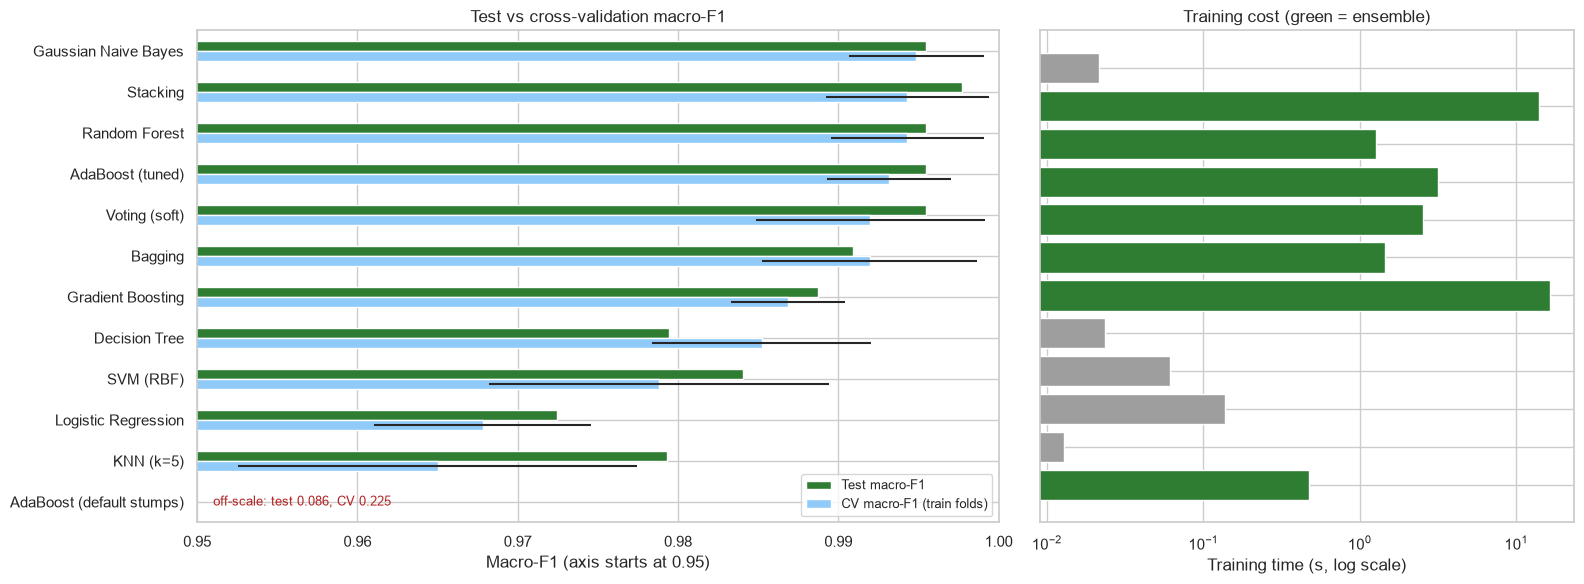

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={"width_ratios": [3, 2]})
order = comparison.index
plot_df = comparison[["F1-score", "CV macro-F1 (mean)"]].rename(
    columns={"F1-score": "Test macro-F1", "CV macro-F1 (mean)": "CV macro-F1 (train folds)"})
plot_df.loc[order].plot.barh(ax=axes[0], xerr={"CV macro-F1 (train folds)": comparison["CV macro-F1 (std)"]},
                             color=["#2e7d32", "#90caf9"])
axes[0].invert_yaxis(); axes[0].set_xlim(0.95, 1.0)
axes[0].set(xlabel="Macro-F1 (axis starts at 0.95)", ylabel="", title="Test vs cross-validation macro-F1")
axes[0].legend(loc="lower right", fontsize=9)
for k, name in enumerate(order):   # label models whose scores fall below the zoomed axis
    if comparison.loc[name, "F1-score"] < 0.95:
        axes[0].text(0.951, k, f"off-scale: test {comparison.loc[name, 'F1-score']:.3f}, "
                     f"CV {comparison.loc[name, 'CV macro-F1 (mean)']:.3f}", va="center", fontsize=9, color="firebrick")

colors = ["#2e7d32" if t == "Ensemble" else "#9e9e9e" for t in comparison.loc[order, "Type"]]
axes[1].barh(order, comparison.loc[order, "Training time (s)"], color=colors)
axes[1].invert_yaxis(); axes[1].set_xscale("log")
axes[1].set(xlabel="Training time (s, log scale)", title="Training cost (green = ensemble)")
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()

## 7. Selected model evaluation
Detailed evaluation of the ensemble model selected in Section 6 for Harvestify integration, on the held-out test set.


In [53]:
best_model = fitted[best_name]
y_pred_best = test_preds[best_name]
print(f"Selected ensemble model: {best_name}\n")
print(comparison.loc[best_name, ["Accuracy", "Precision", "Recall", "F1-score",
                                 "CV macro-F1 (mean)", "Training time (s)"]].round(4).to_string(), "\n")
print(classification_report(y_test, y_pred_best, digits=3, zero_division=0))

Selected ensemble model: Random Forest

Accuracy              0.9955
Precision             0.9957
Recall                0.9955
F1-score              0.9955
CV macro-F1 (mean)    0.9943
Training time (s)     1.2749 

              precision    recall  f1-score   support

       apple      1.000     1.000     1.000        20
      banana      1.000     1.000     1.000        20
   blackgram      1.000     0.950     0.974        20
    chickpea      1.000     1.000     1.000        20
     coconut      1.000     1.000     1.000        20
      coffee      1.000     1.000     1.000        20
      cotton      1.000     1.000     1.000        20
      grapes      1.000     1.000     1.000        20
        jute      0.952     1.000     0.976        20
 kidneybeans      1.000     1.000     1.000        20
      lentil      1.000     1.000     1.000        20
       maize      0.952     1.000     0.976        20
       mango      1.000     1.000     1.000        20
   mothbeans      1.000    

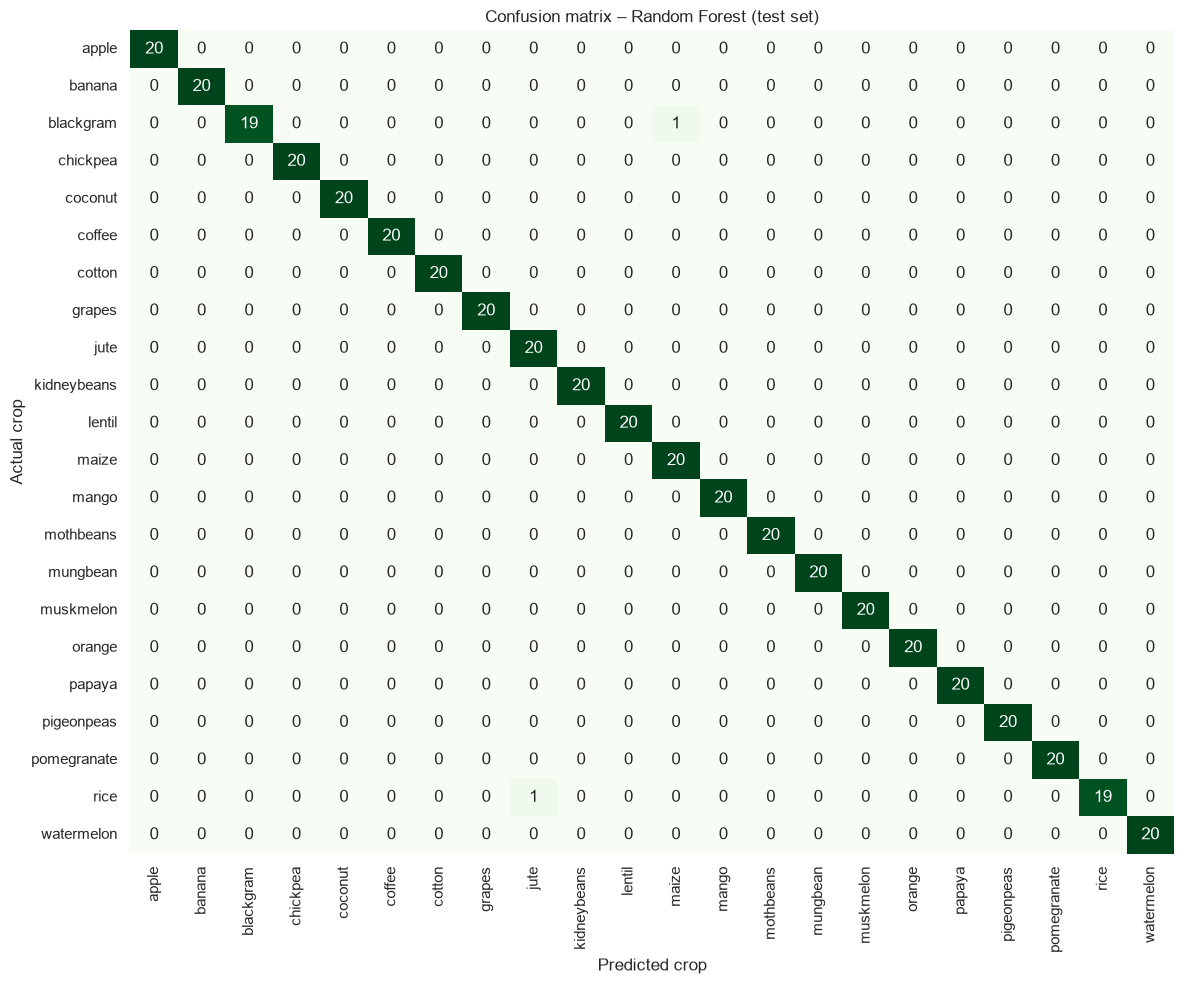

Misclassified: 2 of 440 test samples
  blackgram -> predicted as maize: 1
  rice -> predicted as jute: 1


In [54]:
labels = sorted(y.unique())
cm = confusion_matrix(y_test, y_pred_best, labels=labels)   # rows = actual, columns = predicted

plt.figure(figsize=(12, 10))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", cbar=False, xticklabels=labels, yticklabels=labels)
plt.title(f"Confusion matrix – {best_name} (test set)")
plt.xlabel("Predicted crop"); plt.ylabel("Actual crop")
plt.tight_layout(); plt.show()

errors = [(labels[i], labels[j], cm[i, j]) for i in range(len(labels)) for j in range(len(labels))
          if i != j and cm[i, j] > 0]
print(f"Misclassified: {cm.sum() - np.trace(cm)} of {cm.sum()} test samples")
for actual, predicted, n in errors:
    print(f"  {actual} -> predicted as {predicted}: {n}")

In [55]:
print(test_preds.keys())

dict_keys(['Gaussian Naive Bayes', 'Logistic Regression', 'Decision Tree', 'KNN (k=5)', 'SVM (RBF)', 'Bagging', 'Random Forest', 'AdaBoost (default stumps)', 'Gradient Boosting', 'Voting (soft)', 'Stacking', 'AdaBoost (tuned)'])


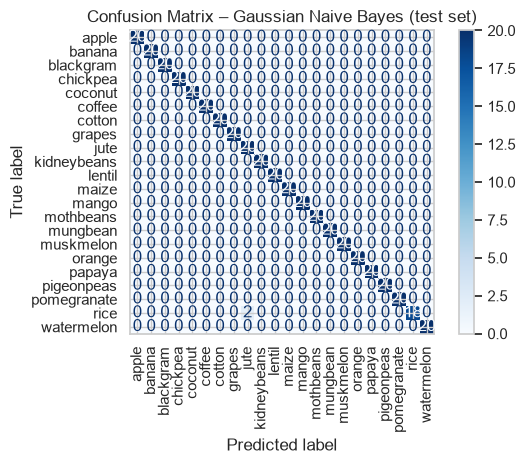

In [56]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_preds["Gaussian Naive Bayes"],
    display_labels=sorted(pd.unique(y_test)),
    xticks_rotation=90,
    cmap="Blues"
)
plt.title("Confusion Matrix – Gaussian Naive Bayes (test set)")
plt.tight_layout()
plt.show()

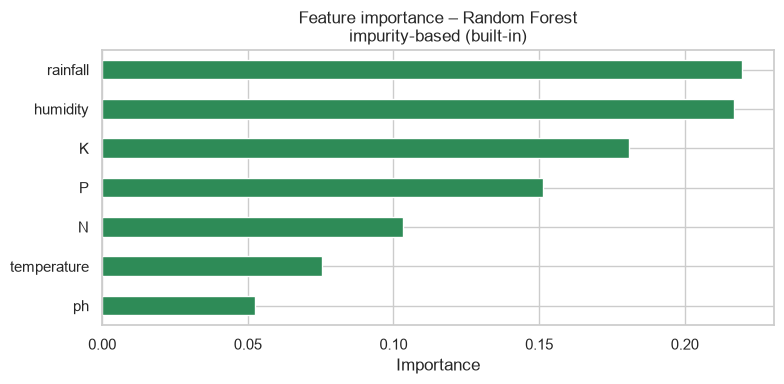

rainfall       0.2196
humidity       0.2171
K              0.1808
P              0.1513
N              0.1034
temperature    0.0755
ph             0.0523


In [57]:
# Built-in importance where the model provides it; otherwise model-agnostic permutation importance
final_step = best_model[-1] if hasattr(best_model, "steps") else best_model
if hasattr(final_step, "feature_importances_"):
    importance, method = pd.Series(final_step.feature_importances_, index=FEATURES), "impurity-based (built-in)"
else:
    perm = permutation_importance(best_model, X_test, y_test, scoring="f1_macro",
                                  n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
    importance, method = pd.Series(perm.importances_mean, index=FEATURES), "permutation (drop in test macro-F1)"

importance = importance.sort_values()
importance.plot.barh(figsize=(8, 4), color="seagreen")
plt.title(f"Feature importance – {best_name}\n{method}"); plt.xlabel("Importance")
plt.tight_layout(); plt.show()
print(importance.sort_values(ascending=False).round(4).to_string())

In [58]:
# Save the selected ensemble model; any preprocessing it needs (for example a scaler) is inside the saved object
MODEL_DIR.mkdir(exist_ok=True)
model_path = MODEL_DIR / "pbl3_best_crop_model.joblib"
info_path = MODEL_DIR / "pbl3_best_crop_model_info.json"

joblib.dump(best_model, model_path)
info = {
    "model": best_name,
    "role": "best-performing ensemble model selected for Harvestify integration",
    "selection_rule": ("among ensembles, mean 5-fold CV macro-F1 on the training set; models within 0.001 "
                       "of the top score are tied; ties -> shorter training time"),
    "tied_ensembles": tied_ensembles,
    "highest_cv_overall": top_cv_model,
    "preprocessing": ("StandardScaler(s) are inside the saved model; pass raw feature values"
                      if any(isinstance(v, StandardScaler) for v in best_model.get_params(deep=True).values())
                      else "none required (scale-invariant model); pass raw feature values"),
    "feature_order": FEATURES,
    "classes": sorted(best_model.classes_.tolist()),
    "test_metrics": comparison.loc[best_name, ["Accuracy", "Precision", "Recall", "F1-score"]].round(4).to_dict(),
    "cv_macro_f1_mean": round(float(comparison.loc[best_name, "CV macro-F1 (mean)"]), 4),
    "random_state": RANDOM_STATE, "test_size": 0.20, "sklearn_version": sklearn.__version__,
}
info_path.write_text(json.dumps(info, indent=2))

# Verify: reload the file and confirm it reproduces the test predictions
reloaded = joblib.load(model_path)
print("Saved:", model_path.relative_to(ROOT), f"({model_path.stat().st_size / 1024:.0f} KB)")
print("Saved:", info_path.relative_to(ROOT))
print("Preprocessing:", info["preprocessing"])
print("Reloaded model reproduces test predictions:", bool((reloaded.predict(X_test) == y_pred_best).all()))
sample = pd.DataFrame([[90, 42, 43, 20.9, 82.0, 6.5, 202.9]], columns=FEATURES)
print("Example prediction for", sample.iloc[0].to_dict(), "->", reloaded.predict(sample)[0])

Saved: models\pbl3_best_crop_model.joblib (7110 KB)
Saved: models\pbl3_best_crop_model_info.json
Preprocessing: none required (scale-invariant model); pass raw feature values
Reloaded model reproduces test predictions: True
Example prediction for {'N': 90.0, 'P': 42.0, 'K': 43.0, 'temperature': 20.9, 'humidity': 82.0, 'ph': 6.5, 'rainfall': 202.9} -> rice


## 8. Results, interpretation and conclusion


In [59]:
base = comparison[comparison["Type"] == "Baseline"]
ens = comparison[comparison["Type"] == "Ensemble"]
for label, name in [("Highest CV overall (baseline)", base.index[0]),
                    ("Selected ensemble", best_name),
                    *[("Tied ensemble", n) for n in tied_ensembles if n != best_name]]:
    r = comparison.loc[name]
    print(f"{label:30s} {name:22s} test F1 {r['F1-score']:.4f} | CV F1 {r['CV macro-F1 (mean)']:.4f} "
          f"| training {r['Training time (s)']:.2f}s")
print("Models tied within 0.001 of the top CV score:", tied_overall)
for other in [n for n in tied_ensembles if n != best_name]:
    ratio = comparison.loc[other, "Training time (s)"] / comparison.loc[best_name, "Training time (s)"]
    print(f"{best_name} trained {ratio:.1f}x faster than {other} in this run")
print(f"Ensembles with test macro-F1 >= 0.99: {int((ens['F1-score'] >= 0.99).sum())} of {len(ens)}")
print(f"AdaBoost test macro-F1: default {comparison.loc['AdaBoost (default stumps)', 'F1-score']:.4f} "
      f"-> tuned {comparison.loc['AdaBoost (tuned)', 'F1-score']:.4f}")
print(f"Single Decision Tree -> Random Forest test macro-F1: {comparison.loc['Decision Tree', 'F1-score']:.4f} "
      f"-> {comparison.loc['Random Forest', 'F1-score']:.4f}")

# Why can Naive Bayes compete? It assumes features are independent within each class
within = [g[FEATURES].corr().where(~np.eye(len(FEATURES), dtype=bool)).abs().stack().mean()
          for _, g in df.groupby(TARGET)]
print(f"Mean |correlation| between features within a crop: {np.mean(within):.3f} "
      f"(overall data: {df[FEATURES].corr().where(~np.eye(len(FEATURES), dtype=bool)).abs().stack().mean():.3f})")

Highest CV overall (baseline)  Gaussian Naive Bayes   test F1 0.9954 | CV F1 0.9949 | training 0.02s
Selected ensemble              Random Forest          test F1 0.9955 | CV F1 0.9943 | training 1.27s
Tied ensemble                  Stacking               test F1 0.9977 | CV F1 0.9943 | training 14.03s
Models tied within 0.001 of the top CV score: ['Gaussian Naive Bayes', 'Random Forest', 'Stacking']
Random Forest trained 11.0x faster than Stacking in this run
Ensembles with test macro-F1 >= 0.99: 5 of 7
AdaBoost test macro-F1: default 0.0856 -> tuned 0.9955
Single Decision Tree -> Random Forest test macro-F1: 0.9794 -> 0.9955
Mean |correlation| between features within a crop: 0.075 (overall data: 0.141)


In [60]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC

models = {
    "Gaussian NB": GaussianNB(),
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000, random_state=42)
    ),
    "KNN (k=5)": make_pipeline(
        StandardScaler(), KNeighborsClassifier(n_neighbors=5)
    ),
    "SVM (RBF)": make_pipeline(
        StandardScaler(), SVC(kernel="rbf", random_state=42)
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, model in models.items():
    scores = cross_val_score(
        model, X_train, y_train,
        cv=cv, scoring="accuracy", n_jobs=-1
    )
    print(f"{name}: {scores.mean()*100:.2f}%")

Gaussian NB: 99.49%
Logistic Regression: 96.82%
KNN (k=5): 96.53%
SVM (RBF): 97.90%


In [61]:
print(test_preds.keys())

dict_keys(['Gaussian Naive Bayes', 'Logistic Regression', 'Decision Tree', 'KNN (k=5)', 'SVM (RBF)', 'Bagging', 'Random Forest', 'AdaBoost (default stumps)', 'Gradient Boosting', 'Voting (soft)', 'Stacking', 'AdaBoost (tuned)'])


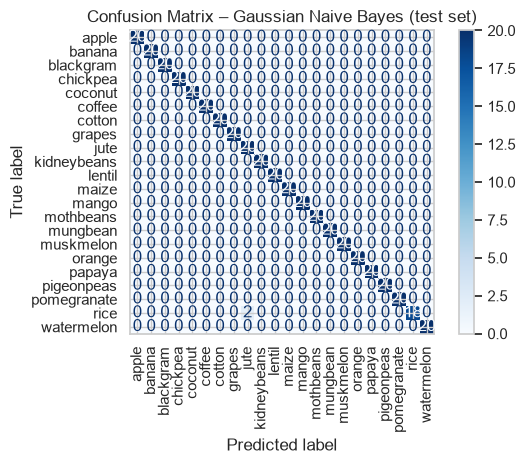

In [62]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test,
    test_preds["Gaussian Naive Bayes"],
    display_labels=sorted(pd.unique(y_test)),
    xticks_rotation=90,
    cmap="Blues"
)

plt.title("Confusion Matrix – Gaussian Naive Bayes (test set)")
plt.tight_layout()
plt.show()

In [64]:
print(comparison.loc[
    ["Random Forest", "Gradient Boosting"],
    ["CV macro-F1 (mean)", "CV macro-F1 (std)"]
].round(4))

                   CV macro-F1 (mean)  CV macro-F1 (std)
Model                                                   
Random Forest                  0.9943             0.0048
Gradient Boosting              0.9869             0.0036


In [82]:
print("Available variables:")
print([v for v in globals() if "grid" in v.lower() or "cv" in v.lower()])

Available variables:
['CalibratedClassifierCV', 'GridSearchCV', 'cv', 'ada_grid', 'grid', 'cv_scores', 'top_cv_model']


In [83]:
for name, scores in cv_scores.items():
    if name in ["Random Forest", "Gradient Boosting"]:
        print(name, "CV macro-F1:", round(scores.mean(), 4),
              "| Std:", round(scores.std(), 4))

Random Forest CV macro-F1: 0.9943 | Std: 0.0048
Gradient Boosting CV macro-F1: 0.9869 | Std: 0.0036


All figures quoted below come from the executed outputs above.

### Key results
- **Ensembles beat the single models they are built from.** A single Decision Tree reaches a test macro-F1 of 0.979. Bagging (0.991) and Random Forest (0.996) improve on it by averaging many de-correlated trees, which reduces the variance of a single tree.
- **Highest CV result overall: Gaussian Naive Bayes, a baseline** (CV macro-F1 0.9949, test accuracy 99.55%). Its CV score is only 0.0006 above Random Forest and Stacking (both 0.9943). All three are therefore within the 0.001 tie threshold, and **no model is clearly best overall**.
- **Selected model: Random Forest, the best-performing ensemble model selected for Harvestify integration.** Test accuracy 99.55%, macro-F1 0.996, CV macro-F1 0.994 ± 0.005. Only 2 of 440 test samples are misclassified: one blackgram as maize and one rice as jute.
- **Why Random Forest rather than Stacking:** the two tie on CV macro-F1, and Random Forest trains several times faster. Wall-clock timings vary between runs (roughly 4–10× in our runs); the ratio for this run is printed in the summary cell. Stacking has a slightly higher *test* accuracy (99.77%, one error), but one test sample (0.23 points) is within normal sampling noise and was not used for selection. Stacking remains an equally valid alternative.
- **AdaBoost** illustrates the importance of the weak learner. With default depth-1 stumps it collapses (accuracy 17.5%, only 6 of 22 crops ever predicted). With depth-4 trees chosen by cross-validation it reaches 99.55%, matching the best models.
- **Gradient Boosting** (98.86%) is accurate but the slowest model, because it builds one tree per class at every boosting stage (22 × 100 trees).
- **Why the Naive Bayes baseline can match the ensembles:** within each crop the features are almost uncorrelated (mean |r| ≈ 0.08, summary cell above), which is exactly Naive Bayes' independence assumption. On this dataset the ensembles' advantage over the *strongest* baseline is therefore robustness and flexibility rather than a large accuracy gain. They do clearly outperform the other four baselines.

### Interpretation
- **Feature importance.** Rainfall and humidity are the most informative features, followed by K and P. Temperature and pH contribute least. This matches the crop-profile heatmap: crops such as rice (very high rainfall), chickpea and kidney beans (very low humidity), and apple and grapes (very high K and P) are separated by these features.
- **Remaining errors** occur between crops with overlapping growing conditions (rice and jute are both high-rainfall, high-humidity crops), not at random.
- **Recommendation for Harvestify:** Random Forest. It ties for the top CV score among ensembles, trains several times faster than Stacking, needs no feature scaling, provides built-in feature importances, and is already the algorithm used in Harvestify's crop recommendation workflow, so integrating it needs no change of approach.

### Limitations
- The dataset is small, perfectly balanced and highly separable. In the project's data-preparation notebook (`Final_recommendationdata_creation.ipynb`), N, P and K were partly generated from per-crop reference values plus random noise. Near-perfect scores here therefore **do not demonstrate real-world accuracy**, which would need validation on field data.
- Results come from one stratified split of 440 test samples. Cross-validation is reported to show stability, but differences below about 0.005 between the top models should not be over-interpreted.
- The tuned AdaBoost's CV score uses the same folds that selected its settings, so it is slightly optimistic.

### Conclusion
Ensemble learning improved substantially on single decision trees and on four of the five baselines, provided the ensemble was configured sensibly (as the AdaBoost investigation shows). The top results (Gaussian Naive Bayes, Random Forest and Stacking) are statistically tied. Gaussian Naive Bayes has the marginally highest CV score overall, while **Random Forest is the best-performing ensemble model selected for Harvestify integration**, chosen for its tied top ensemble score, much lower training cost and existing use in Harvestify. It was saved for reuse as `models/pbl3_best_crop_model.joblib`.
